# 02 · Modélisation

**Objectif** : comparer plusieurs modèles pour estimer, à une date de coupure, la probabilité qu'un joueur actif ne revienne plus dans les 3 mois (`churn_3m`).

**Démarche** (axes 4 et 5) :
1. Split chronologique : **entraînement** = coupure du 1er avril 2008, **test** = coupure du 1er juillet 2008. Le test n'est utilisé qu'une seule fois, à la fin.
2. Toute la préparation (imputation, standardisation, encodage) est dans un `Pipeline`, ajusté sur l'entraînement uniquement.
3. Baselines : `DummyClassifier` et la règle métier actuelle (« relancer les joueurs absents depuis plus de 14 jours »).
4. Modèles : régression logistique, arbre de décision sans limite (pour illustrer le surapprentissage), Random Forest réglé par validation croisée.
5. Validation croisée stratifiée à 5 folds sur l'entraînement : moyenne et écart-type.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import build_dataset, load_raw
from modeling import CAT_COLS, NUM_COLS, TARGET, make_preprocessor, rule_14_days

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
FIG = ROOT / "reports" / "figures"
PRED = ROOT / "reports" / "predictions"
FIG.mkdir(parents=True, exist_ok=True)
PRED.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. Construction des jeux d'entraînement et de test (split chronologique)

In [2]:
df = load_raw()
train = build_dataset(df, "2008-04-01")  # variables : janv.-mars ; cible : avril-juin
test = build_dataset(df, "2008-07-01")   # variables : avril-juin ; cible : juillet-sept.
del df

X_train, y_train = train[NUM_COLS + CAT_COLS], train[TARGET]
X_test, y_test = test[NUM_COLS + CAT_COLS], test[TARGET]

print(f"Entraînement : {len(train):,} joueurs, churn = {y_train.mean():.1%}")
print(f"Test         : {len(test):,} joueurs, churn = {y_test.mean():.1%}")
print(f"Joueurs présents dans les deux jeux : {len(set(train['char']) & set(test['char'])):,}")

Entraînement : 8,265 joueurs, churn = 31.4%
Test         : 6,918 joueurs, churn = 26.1%
Joueurs présents dans les deux jeux : 3,870


**Lecture** : le split est **chronologique**, pas aléatoire. Le modèle apprend sur le printemps et il est jugé sur l'été, comme il le serait en production. Une partie des joueurs apparaît dans les deux jeux, mais à des dates différentes, avec des variables recalculées et une cible différente : il n'y a pas de fuite de la cible, c'est exactement la situation d'un modèle réutilisé d'un trimestre à l'autre.

Le taux de churn est un peu plus bas en été (26 % contre 31 %) : le test vérifie donc aussi la robustesse du modèle à un changement de période.

**Variables utilisées** : 12 numériques et 2 catégorielles (race, classe). `char` (identifiant) et `date_coupure` sont exclues (voir l'audit de fuite du notebook 01).

## 2. Choix de la métrique (axe 5)

- **Métrique principale : PR-AUC** (`average_precision`). Elle mesure la capacité à classer les joueurs qui partent avant les autres, indépendamment du seuil. Elle est plus exigeante que la ROC-AUC quand la classe positive est minoritaire (31 %). C'est elle qui départage les modèles.
- **Garde-fous** : Recall (part des départs repérés, critère de succès ≥ 70 %), Precision (part des offres utiles, critère ≥ 33 %), F1 et ROC-AUC.
- **Accuracy** : non utilisée. Un modèle qui prédit toujours « reste » ferait déjà 69 % d'accuracy sans repérer aucun départ.
- Le **seuil de décision** sera choisi par le coût métier dans le notebook 03 : à ce stade, F1, Recall et Precision sont calculés au seuil par défaut de 0,5.

## 3. Baselines et modèles en validation croisée (5 folds)

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1",
           "Recall": "recall", "Precision": "precision"}

modeles = {
    "Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": Pipeline([("prep", make_preprocessor()),
                                       ("clf", LogisticRegression(max_iter=2000))]),
    "Arbre sans max_depth": Pipeline([("prep", make_preprocessor()),
                                      ("clf", DecisionTreeClassifier(random_state=SEED))]),
    "Random Forest (max_depth=8)": Pipeline([("prep", make_preprocessor()),
                                             ("clf", RandomForestClassifier(n_estimators=200, max_depth=8,
                                                                            random_state=SEED, n_jobs=-1))]),
}

lignes = []
for nom, modele in modeles.items():
    res = cross_validate(modele, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    ligne = {"Modèle": nom, "PR-AUC train": res["train_PR-AUC"].mean()}
    for m in scoring:
        ligne[f"{m} CV"] = f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
    lignes.append(ligne)

# Règle actuelle : évaluée sur les mêmes folds
regle = {m: [] for m in ["F1", "Recall", "Precision"]}
for _, idx_val in cv.split(X_train, y_train):
    y_v, p_v = y_train.iloc[idx_val], rule_14_days(X_train.iloc[idx_val])
    regle["F1"].append(f1_score(y_v, p_v))
    regle["Recall"].append(recall_score(y_v, p_v))
    regle["Precision"].append(precision_score(y_v, p_v))
lignes.insert(1, {"Modèle": "Règle actuelle (absent > 14 j)", "PR-AUC train": np.nan, "PR-AUC CV": "—", "ROC-AUC CV": "—",
                  **{f"{m} CV": f"{np.mean(v):.3f} ± {np.std(v):.3f}" for m, v in regle.items()}})

comparaison = pd.DataFrame(lignes).set_index("Modèle")
comparaison["PR-AUC train"] = comparaison["PR-AUC train"].round(3)
with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(comparaison)

,PR-AUC train,PR-AUC CV,ROC-AUC CV,F1 CV,Recall CV,Precision CV
Modèle,,,,,,
Baseline (classe majoritaire),0.314,0.314 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Règle actuelle (absent > 14 j),NaN,—,—,0.536 ± 0.013,0.506 ± 0.021,0.570 ± 0.006
Régression logistique,0.738,0.736 ± 0.018,0.870 ± 0.006,0.679 ± 0.007,0.667 ± 0.010,0.692 ± 0.013
Arbre sans max_depth,1.000,0.481 ± 0.014,0.705 ± 0.012,0.595 ± 0.017,0.598 ± 0.023,0.592 ± 0.013
Random Forest (max_depth=8),0.859,0.770 ± 0.018,0.884 ± 0.005,0.669 ± 0.016,0.608 ± 0.023,0.744 ± 0.021


**Lecture** :
- **Baseline** : PR-AUC de 0,314, soit exactement le taux de churn (ce que donne un classement au hasard), et Recall de 0 : elle ne repère aucun départ. C'est le plancher.
- **Règle actuelle** (absent depuis plus de 14 jours) : elle ne repère qu'un départ sur deux (Recall ≈ 0,51), et 43 % de ses offres partent chez des joueurs qui seraient restés. C'est la référence métier à battre.
- **Régression logistique** : PR-AUC de 0,736 ± 0,018, avec un score train presque identique (0,738). Le modèle est stable, sans surapprentissage, et interprétable.
- **Arbre sans `max_depth`** : PR-AUC de 1,00 en train contre 0,48 en validation. C'est un **surapprentissage net** : l'arbre apprend les joueurs par cœur au lieu de règles générales.
- **Random Forest** (`max_depth=8`) : le meilleur PR-AUC en validation (0,770 ± 0,018). L'écart train/validation (0,86 contre 0,77) reste raisonnable.
- Au seuil de 0,5, la régression logistique a un meilleur Recall que le Random Forest, mais une moins bonne Precision. Ces métriques dépendent du seuil, d'où le choix du PR-AUC comme métrique principale et du seuil par le coût (notebook 03).

## 4. Réglage des hyperparamètres du Random Forest

In [4]:
rf = Pipeline([("prep", make_preprocessor()),
               ("clf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])
grille = {"clf__max_depth": [4, 8, 12, None], "clf__min_samples_leaf": [1, 5, 20]}
recherche = GridSearchCV(rf, grille, cv=cv, scoring="average_precision", return_train_score=True)
recherche.fit(X_train, y_train)

resultats = pd.DataFrame(recherche.cv_results_)
resultats = resultats.rename(columns={"param_clf__max_depth": "max_depth", "param_clf__min_samples_leaf": "min_samples_leaf",
                                      "mean_train_score": "PR-AUC train", "mean_test_score": "PR-AUC CV",
                                      "std_test_score": "écart-type CV"})
resultats["max_depth"] = [("None" if pd.isna(v) else str(int(v))) for v in resultats["max_depth"]]
display(resultats[["max_depth", "min_samples_leaf", "PR-AUC train", "PR-AUC CV", "écart-type CV"]].round(3))
print("Meilleurs hyperparamètres :", recherche.best_params_, f"PR-AUC CV = {recherche.best_score_:.3f}")

,max_depth,min_samples_leaf,PR-AUC train,PR-AUC CV,écart-type CV
0,4,1,0.771,0.761,0.019
1,4,5,0.771,0.761,0.019
2,4,20,0.771,0.760,0.019
3,8,1,0.859,0.770,0.018
4,8,5,0.840,0.770,0.017
5,8,20,0.810,0.771,0.017
6,12,1,0.965,0.773,0.014
7,12,5,0.896,0.775,0.015
8,12,20,0.822,0.773,0.017
9,None,1,1.000,0.765,0.010


Meilleurs hyperparamètres : {'clf__max_depth': None, 'clf__min_samples_leaf': 5} PR-AUC CV = 0.776


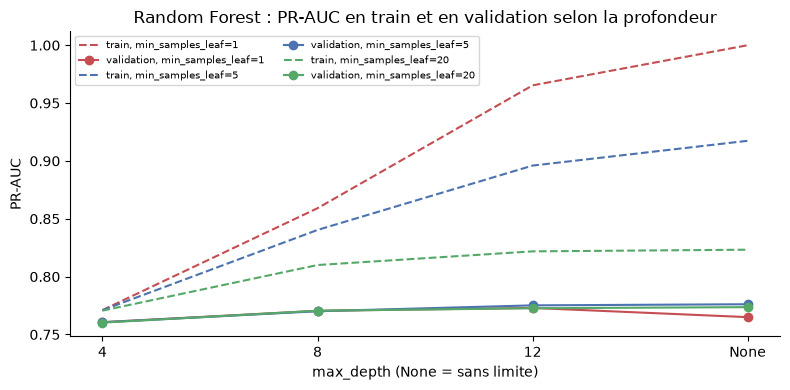

In [5]:
fig, ax = plt.subplots()
for leaf, couleur in [(1, "#C44E52"), (5, "#4C72B0"), (20, "#55A868")]:
    sous = resultats[resultats["min_samples_leaf"] == leaf]
    ax.plot(sous["max_depth"], sous["PR-AUC train"], "--", color=couleur, label=f"train, min_samples_leaf={leaf}")
    ax.plot(sous["max_depth"], sous["PR-AUC CV"], "-o", color=couleur, label=f"validation, min_samples_leaf={leaf}")
ax.set_title("Random Forest : PR-AUC en train et en validation selon la profondeur")
ax.set_xlabel("max_depth (None = sans limite)")
ax.set_ylabel("PR-AUC")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(FIG / "06_rf_train_vs_cv.png", dpi=150)
plt.show()

**Lecture** : plus les arbres sont profonds, plus le score en train grimpe (jusqu'à 1,00 sans limite et avec `min_samples_leaf=1`), alors que le score en validation plafonne autour de 0,77. Imposer au moins 5 joueurs par feuille limite ce surapprentissage.

La meilleure combinaison (`max_depth=None`, `min_samples_leaf=5`) obtient 0,776 en validation. Les combinaisons voisines sont à moins d'un écart-type (≈ 0,015) : le résultat ne dépend pas d'un réglage très fin. L'écart train/validation reste visible (0,92 contre 0,78) ; une version plus contrainte (`max_depth=12`, `min_samples_leaf=20`) ferait presque aussi bien (0,773) avec moins d'écart, ce serait un choix défendable si l'on privilégiait la robustesse.

## 5. Modèle retenu et diagnostic

Le **Random Forest réglé** est retenu : meilleur PR-AUC en validation croisée, stable d'un fold à l'autre. La régression logistique reste une alternative crédible, un peu moins performante mais plus simple à expliquer.

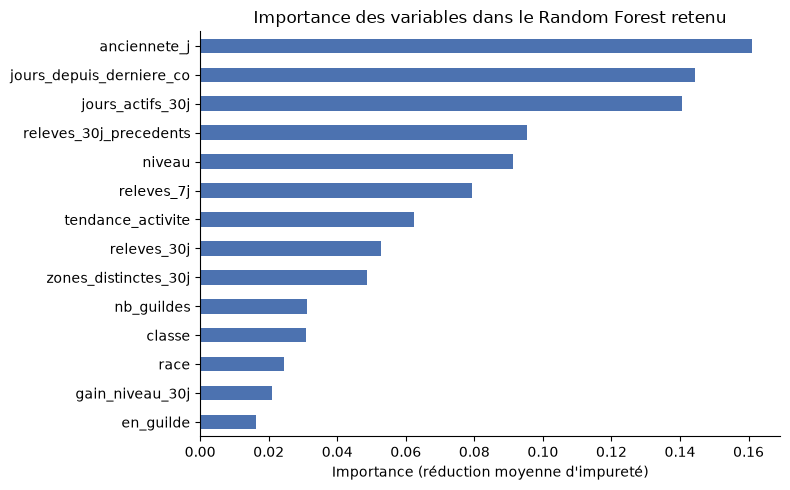

In [6]:
modele_final = recherche.best_estimator_

# Probabilités hors échantillon : utilisées pour choisir le seuil (notebook 03)
proba_oof = cross_val_predict(modele_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Importance des variables
noms = modele_final.named_steps["prep"].get_feature_names_out()
imp = pd.Series(modele_final.named_steps["clf"].feature_importances_, index=noms)
imp.index = [n.split("__")[1] for n in imp.index]
imp = imp.groupby(lambda n: next((c for c in CAT_COLS if n.startswith(c + "_")), n)).sum().sort_values()

ax = imp.plot(kind="barh", color="#4C72B0", figsize=(8, 5))
ax.set_title("Importance des variables dans le Random Forest retenu")
ax.set_xlabel("Importance (réduction moyenne d'impureté)")
plt.tight_layout()
plt.savefig(FIG / "07_importance_variables.png", dpi=150)
plt.show()

**Lecture** : les variables les plus utiles sont l'ancienneté, la récence de la dernière connexion et la régularité (jours actifs sur 30 jours), puis l'activité passée et le niveau. La race et la classe du personnage pèsent peu (environ 3 % chacune) : ce sont le **comportement** et l'**engagement** qui annoncent un départ, pas le profil. C'est rassurant pour l'équité du modèle et c'est actionnable pour l'équipe rétention.

`en_guilde` paraît peu importante alors que le lien avec le churn était fort dans le notebook 01 : c'est parce que `nb_guildes` porte presque la même information, et deux variables corrélées se partagent l'importance. Cette mesure d'importance est indicative, pas une preuve causale.

In [7]:
# Analyse des erreurs (prédictions hors échantillon, seuil 0,5)
pred_oof = (proba_oof >= 0.5).astype(int)
groupes = np.select([(y_train == 1) & (pred_oof == 1), (y_train == 1) & (pred_oof == 0),
                     (y_train == 0) & (pred_oof == 1), (y_train == 0) & (pred_oof == 0)],
                    ["Départ repéré (TP)", "Départ manqué (FN)", "Fausse alerte (FP)", "Fidèle bien classé (TN)"], default="")
profil = (train.assign(groupe=groupes)
          .groupby("groupe")[["jours_depuis_derniere_co", "jours_actifs_30j", "anciennete_j", "niveau", "en_guilde"]]
          .mean().round(1))
profil["effectif"] = pd.Series(groupes).value_counts()
with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(profil)

,jours_depuis_derniere_co,jours_actifs_30j,anciennete_j,niveau,en_guilde,effectif
groupe,,,,,,
Départ manqué (FN),12.2,4.1,61.6,31.7,0.5,983
Départ repéré (TP),15.5,1.6,20.8,9.3,0.1,1614
Fausse alerte (FP),15.6,1.9,28.6,16.3,0.2,562
Fidèle bien classé (TN),5.0,11.5,72.0,47.1,0.7,5106


**Lecture des erreurs** :
- Les **départs manqués (FN)** sont des joueurs « intermédiaires » : plus anciens (≈ 62 jours d'historique), de niveau moyen (≈ 32), modérément actifs (≈ 4 jours de jeu sur 30) et en guilde une fois sur deux. Leur profil est à mi-chemin entre les fidèles et les partants : leur décrochage est peu visible dans l'activité.
- Les **fausses alertes (FP)** ont presque le même profil que les vrais départs : très peu actifs (≈ 2 jours sur 30), récents, bas niveau, rarement en guilde. Ce sont des joueurs occasionnels qui finissent par revenir. Leur envoyer une offre n'est pas absurde, mais cela a un coût, chiffré dans le notebook 03.
- Piste d'amélioration : des variables sur l'évolution récente du joueur intermédiaire (baisse du temps de session, départ de guilde) pour mieux repérer les FN.

## 6. Évaluation finale sur le test (une seule fois)

Le modèle retenu, entraîné sur toute la coupure d'avril, est évalué **une seule fois** sur la coupure de juillet, jamais utilisée jusqu'ici.

PR-AUC test  : 0.717  (validation croisée : 0.776)
ROC-AUC test : 0.881
PR-AUC de la baseline (taux de churn du test) : 0.261


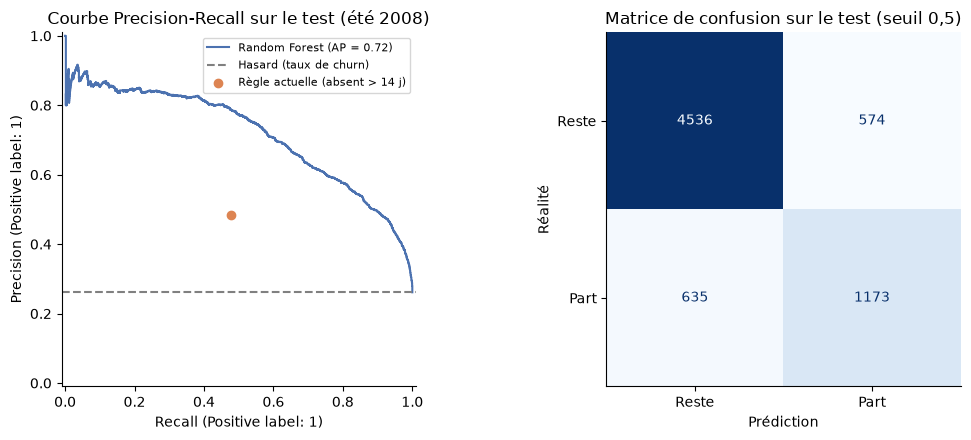

In [8]:
proba_test = modele_final.predict_proba(X_test)[:, 1]
print(f"PR-AUC test  : {average_precision_score(y_test, proba_test):.3f}  (validation croisée : {recherche.best_score_:.3f})")
print(f"ROC-AUC test : {roc_auc_score(y_test, proba_test):.3f}")
print(f"PR-AUC de la baseline (taux de churn du test) : {y_test.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[0], name="Random Forest", color="#4C72B0")
axes[0].axhline(y_test.mean(), color="grey", ls="--", label="Hasard (taux de churn)")
regle_test = rule_14_days(X_test)
axes[0].scatter(recall_score(y_test, regle_test), precision_score(y_test, regle_test), color="#DD8452",
                zorder=3, label="Règle actuelle (absent > 14 j)")
axes[0].set_title("Courbe Precision-Recall sur le test (été 2008)")
axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= 0.5).astype(int), ax=axes[1], cmap="Blues",
                                        display_labels=["Reste", "Part"], colorbar=False)
axes[1].set_title("Matrice de confusion sur le test (seuil 0,5)")
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Réalité")
plt.tight_layout()
plt.savefig(FIG / "08_test_pr_confusion.png", dpi=150)
plt.show()

**Lecture** :
- Sur l'été, une période jamais vue, le PR-AUC est de 0,717 contre 0,776 en validation croisée, pour une baseline à 0,261. La baisse est attendue : le taux de churn est plus bas (26 % contre 31 %) et la période est différente. L'écart reste modéré et la ROC-AUC est stable (0,88) : le modèle **généralise** d'un trimestre à l'autre.
- Sur la courbe, le point orange (règle actuelle) est nettement **sous** la courbe du modèle : pour le même nombre de départs repérés, le modèle envoie moins d'offres inutiles, et pour la même précision, il repère beaucoup plus de départs.
- Le seuil de 0,5 n'est qu'un point de cette courbe : le notebook 03 choisit le seuil en fonction des coûts.

In [9]:
# Sauvegarde pour le notebook 03
pd.DataFrame({"y": y_train, "proba": proba_oof}).to_csv(PRED / "train_oof.csv", index=False)
pd.DataFrame({"y": y_test, "proba": proba_test, "regle_14j": regle_test}).to_csv(PRED / "test.csv", index=False)
print("Probabilités sauvegardées dans reports/predictions/")

Probabilités sauvegardées dans reports/predictions/
